# Predictive Maintenance Using PySpark and Machine Learning
**Course project: Big Data Analytics** | Dataset: AI4I 2020 Predictive Maintenance (UCI, id 601)

**How to run:** `Runtime -> Run all` (or run cells top to bottom with Shift+Enter). The first cell installs Java/PySpark and takes 1-3 minutes.

**What this notebook does:** loads the real AI4I 2020 data into a Spark DataFrame, explores and cleans it, trains Logistic Regression, Decision Tree and Random Forest with Spark MLlib Pipelines, evaluates them (with failure-class metrics), shows feature importance, demonstrates predictions, and saves/reloads the best pipeline.

**Honesty notes**
* Spark here runs in **local mode** inside one Colab VM (`local[*]` = all CPU cores of that VM). It is **not** a multi-node cluster.
* The dataset has only about 10,000 rows, so it does **not** demonstrate large-scale performance. The code is written with Spark DataFrames/MLlib, which *can* scale to a cluster, but this notebook does not prove that.
* No results are pre-filled. Every number you see comes from running the cells.

## Section 1: Environment setup
Spark runs on the Java Virtual Machine (JVM), so Java must be present. PySpark 3.5.x supports Java 8, 11 and 17, so the cell below checks the installed Java and installs OpenJDK 17 if the version is missing or unsupported (for example Java 21), then installs PySpark.

*Expected output:* detected Java version, then a confirmation that PySpark is installed.

In [4]:
# 1.1 Install Java (only if needed) and PySpark
import os, re, shutil, subprocess, sys

PYSPARK_VERSION = "4.0.0"          # supports Java 8/11/17 and recent Python versions

def get_java_major_version():
    # Returns the major Java version as an integer, or None if Java is not installed.
    if shutil.which("java") is None:
        return None
    out = subprocess.run(["java", "-version"], capture_output=True, text=True)
    text = out.stderr + out.stdout
    match = re.search(r'version "(\d+)(?:\.(\d+))?', text)
    if not match:
        return None
    major = int(match.group(1))
    if major == 1 and match.group(2):      # old style "1.8.0" means Java 8
        major = int(match.group(2))
    return major

java_major = get_java_major_version()
print("Detected Java major version:", java_major)

if java_major not in (8, 11, 17):
    print("Installing OpenJDK 17 (needed by Spark 3.5) ...")
    subprocess.run(["apt-get", "update", "-qq"], check=False)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk-headless"], check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
    java_major = get_java_major_version()
    print("Java major version after install:", java_major)

# Install PySpark only if the pinned version is not already available
try:
    import pyspark
    if pyspark.__version__ != PYSPARK_VERSION:
        raise ImportError("different PySpark version installed")
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"pyspark=={PYSPARK_VERSION}"])
    print("PySpark installed. If the next cells complain about an old version, use Runtime -> Restart session and run again.")

print("Python version:", sys.version.split()[0])
print("Java OK:", java_major in (8, 11, 17))

Detected Java major version: 17
Python version: 3.13.16
Java OK: True


In [5]:

import sys
import pyspark

print("Python version:", sys.version)
print("PySpark version:", pyspark.__version__)

from pyspark.sql import SparkSession
from pyspark.ml.functions import vector_to_array

print("PySpark imports successful!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PySpark version: 4.0.0
PySpark imports successful!


In [3]:

!pip uninstall -y pyspark py4j
!pip install --no-cache-dir pyspark==4.0.0


Found existing installation: pyspark 4.0.0
Uninstalling pyspark-4.0.0:
  Successfully uninstalled pyspark-4.0.0
Found existing installation: py4j 0.10.9.9
Uninstalling py4j-0.10.9.9:
  Successfully uninstalled py4j-0.10.9.9
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.1/434.1 MB 227.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.0/203.0 kB 287.5 MB/s eta 0:00:00
  Created wheel for pyspark: filename=pyspark-4.0.0-py2.py3-none-any.whl size=434741300 sha256=360c0a88684d12b74488a6640df23293a06de5c48f79fa2753c61b178e617224
  Stored in directory: /tmp/pip-ephem-wheel-cache-h4zop3_a/wheels/e4/82/ed/8c205a7ade6132d277fcdaccff39051342fff763b34e90dc8f
Successfully built pyspark


In [1]:
# 1.2 Import libraries and create the SparkSession
import time, platform, zipfile, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

import pyspark
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (SQLTransformer, StringIndexer, OneHotEncoder,
                                VectorAssembler, StandardScaler)
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier)
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array

try:
    from IPython.display import display      # nicer tables in notebooks
except ImportError:
    display = print                          # fallback when run as a plain .py script

SEED = 42   # fixed seed used everywhere for reproducibility

spark = (SparkSession.builder
         .master("local[*]")                              # local mode: all cores of this one machine
         .appName("Predictive_Maintenance_BDA")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")     # small data -> fewer shuffle partitions
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Spark version      :", spark.version)
print("PySpark version    :", pyspark.__version__)
print("Spark master       :", spark.sparkContext.master, "(local mode, single machine)")
print("Default parallelism:", spark.sparkContext.defaultParallelism)

# Sanity check: run a tiny Spark job to prove Spark works
assert spark.range(5).count() == 5
print("Spark is running correctly.")

Spark version      : 4.0.0
PySpark version    : 4.0.0
Spark master       : local[*] (local mode, single machine)
Default parallelism: 2
Spark is running correctly.


## Section 2: Dataset loading
The notebook tries these sources in order:
1. Official UCI zip file (primary).
2. The `ucimlrepo` Python package (fallback 1).
3. Manual upload of `ai4i2020.csv` from your computer (fallback 2; download it from the UCI page first).

Column names are **inspected from the real file** and then mapped to clean snake_case names (spaces/brackets in names like `Air temperature [K]` are awkward in Spark). The code stops with a clear error if an unexpected column appears, instead of guessing.

In [5]:

import os
import shutil
import subprocess

In [6]:
# 2.1 Download the real dataset (primary method + fallbacks)
DATA_DIR = "/content/data" if os.path.isdir("/content") else os.path.abspath("data")
os.makedirs(DATA_DIR, exist_ok=True)
CSV_PATH = os.path.join(DATA_DIR, "ai4i2020.csv")
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

def download_from_uci_zip():
    zip_path = os.path.join(DATA_DIR, "ai4i2020.zip")
    request = urllib.request.Request(UCI_ZIP_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=60) as response, open(zip_path, "wb") as out:
        shutil.copyfileobj(response, out)
    with zipfile.ZipFile(zip_path) as z:
        csv_names = [n for n in z.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV found inside the UCI zip file.")
        with z.open(csv_names[0]) as src, open(CSV_PATH, "wb") as dst:
            shutil.copyfileobj(src, dst)

def download_with_ucimlrepo():
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=601)
    # pandas is used here ONLY to write the downloaded table to a CSV file; Spark reads it next.
    full = pd.concat([dataset.data.ids, dataset.data.features, dataset.data.targets], axis=1)
    full.to_csv(CSV_PATH, index=False)

def manual_upload():
    from google.colab import files
    print("Please choose the file ai4i2020.csv from your computer ...")
    uploaded = files.upload()
    csv_names = [n for n in uploaded if n.lower().endswith(".csv")]
    if not csv_names:
        raise FileNotFoundError("No CSV file was uploaded.")
    shutil.copyfile(csv_names[0], CSV_PATH)

if os.path.exists(CSV_PATH) and os.path.getsize(CSV_PATH) > 0:
    print("Dataset file already present:", CSV_PATH)
else:
    for method in (download_from_uci_zip, download_with_ucimlrepo, manual_upload):
        try:
            print("Trying:", method.__name__)
            method()
            if os.path.exists(CSV_PATH) and os.path.getsize(CSV_PATH) > 0:
                print("Success with", method.__name__)
                break
        except Exception as e:
            print("  Failed:", type(e).__name__, e)

assert os.path.exists(CSV_PATH) and os.path.getsize(CSV_PATH) > 0, "Dataset could not be obtained - see troubleshooting."
print("Dataset file:", CSV_PATH, "-", os.path.getsize(CSV_PATH), "bytes")

Trying: download_from_uci_zip
Success with download_from_uci_zip
Dataset file: /content/data/ai4i2020.csv - 522048 bytes


In [8]:
import re

In [9]:
# 2.2 Load the CSV into a Spark DataFrame and standardise column names
raw_df = spark.read.csv(CSV_PATH, header=True, inferSchema=True)   # transformation + schema inference job
print("Original column names in the file:")
print(raw_df.columns)

def normalise(name):
    # "Air temperature [K]" -> "air temperature"
    name = re.sub(r"\[.*?\]", "", name)
    return re.sub(r"\s+", " ", name).strip().lower()

COLUMN_MAP = {
    "udi": "UDI", "product id": "product_id", "type": "machine_type",
    "air temperature": "air_temp_k", "process temperature": "process_temp_k",
    "rotational speed": "rot_speed_rpm", "torque": "torque_nm", "tool wear": "tool_wear_min",
    "machine failure": "machine_failure",
    "twf": "TWF", "hdf": "HDF", "pwf": "PWF", "osf": "OSF", "rnf": "RNF",
}

new_names = []
for c in raw_df.columns:
    key = normalise(c)
    if key not in COLUMN_MAP:
        raise ValueError(f"Unexpected column '{c}' in the dataset. Please inspect raw_df.columns and update COLUMN_MAP.")
    new_names.append(COLUMN_MAP[key])

missing_expected = set(COLUMN_MAP.values()) - set(new_names)
assert not missing_expected, f"Expected columns not found in the file: {missing_expected}"

df = raw_df.toDF(*new_names)

print("\nColumn name mapping (original -> clean):")
for old, new in zip(raw_df.columns, new_names):
    print(f"  {old!r:32} -> {new}")

Original column names in the file:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Column name mapping (original -> clean):
  'UDI'                            -> UDI
  'Product ID'                     -> product_id
  'Type'                           -> machine_type
  'Air temperature [K]'            -> air_temp_k
  'Process temperature [K]'        -> process_temp_k
  'Rotational speed [rpm]'         -> rot_speed_rpm
  'Torque [Nm]'                    -> torque_nm
  'Tool wear [min]'                -> tool_wear_min
  'Machine failure'                -> machine_failure
  'TWF'                            -> TWF
  'HDF'                            -> HDF
  'PWF'                            -> PWF
  'OSF'                            -> OSF
  'RNF'                            -> RNF


In [10]:
# 2.3 Inspect the loaded data
print("Sample records:")
df.show(5, truncate=False)

print("Schema:")
df.printSchema()

total_records = df.count()          # action: triggers the Spark job
print("Total records:", total_records)
print("Column names :", df.columns)

Sample records:
+---+----------+------------+----------+--------------+-------------+---------+-------------+---------------+---+---+---+---+---+
|UDI|product_id|machine_type|air_temp_k|process_temp_k|rot_speed_rpm|torque_nm|tool_wear_min|machine_failure|TWF|HDF|PWF|OSF|RNF|
+---+----------+------------+----------+--------------+-------------+---------+-------------+---------------+---+---+---+---+---+
|1  |M14860    |M           |298.1     |308.6         |1551         |42.8     |0            |0              |0  |0  |0  |0  |0  |
|2  |L47181    |L           |298.2     |308.7         |1408         |46.3     |3            |0              |0  |0  |0  |0  |0  |
|3  |L47182    |L           |298.1     |308.5         |1498         |49.4     |5            |0              |0  |0  |0  |0  |0  |
|4  |L47183    |L           |298.2     |308.6         |1433         |39.5     |7            |0              |0  |0  |0  |0  |0  |
|5  |L47184    |L           |298.2     |308.7         |1408         |40.0 

## Section 3: Data exploration
All analysis below uses Spark DataFrame operations (`select`, `groupBy`, `agg`, `summary`, ...). Each Spark *transformation* is lazy; an *action* such as `show()` or `count()` triggers execution. Small aggregated results are converted to pandas **only for plotting**.

**Column groups used throughout the notebook**
* `machine_failure` is the **target** (1 = machine failed, 0 = no failure).
* `TWF, HDF, PWF, OSF, RNF` are **failure-mode indicators**. They describe *why* a failure happened, so they are only available after the fact. They must never be model inputs.

In [11]:
# 3.0 Define column groups (used in every later section)
TARGET = "machine_failure"
ID_COLS = ["UDI", "product_id"]
FAILURE_MODE_COLS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
CATEGORICAL_COLS = ["machine_type"]
RAW_NUMERIC_COLS = ["air_temp_k", "process_temp_k", "rot_speed_rpm", "torque_nm", "tool_wear_min"]

# 3.1 Data types, missing values, duplicates
print("Data types:")
for name, dtype in df.dtypes:
    print(f"  {name:18} {dtype}")

# Count nulls (and NaN for floating point columns) in every column
null_exprs = []
for name, dtype in df.dtypes:
    cond = F.col(name).isNull()
    if dtype in ("double", "float"):
        cond = cond | F.isnan(F.col(name))
    null_exprs.append(F.sum(F.when(cond, 1).otherwise(0)).alias(name))
print("\nMissing values per column:")
df.select(null_exprs).show(vertical=True)

# Duplicates
n_rows = df.count()
print("Total rows                                  :", n_rows)
print("Distinct UDI values                         :", df.select("UDI").distinct().count())
print("Distinct product_id values                  :", df.select("product_id").distinct().count())
print("Distinct rows ignoring UDI                  :", df.drop("UDI").distinct().count())
print("Distinct rows ignoring UDI and product_id   :", df.drop("UDI", "product_id").distinct().count())

Data types:
  UDI                int
  product_id         string
  machine_type       string
  air_temp_k         double
  process_temp_k     double
  rot_speed_rpm      int
  torque_nm          double
  tool_wear_min      int
  machine_failure    int
  TWF                int
  HDF                int
  PWF                int
  OSF                int
  RNF                int

Missing values per column:
-RECORD 0--------------
 UDI             | 0   
 product_id      | 0   
 machine_type    | 0   
 air_temp_k      | 0   
 process_temp_k  | 0   
 rot_speed_rpm   | 0   
 torque_nm       | 0   
 tool_wear_min   | 0   
 machine_failure | 0   
 TWF             | 0   
 HDF             | 0   
 PWF             | 0   
 OSF             | 0   
 RNF             | 0   

Total rows                                  : 10000
Distinct UDI values                         : 10000
Distinct product_id values                  : 10000
Distinct rows ignoring UDI                  : 10000
Distinct rows ignoring UDI

In [12]:
# 3.2 Class distribution of the target
print("Class distribution (machine_failure):")
(df.groupBy(TARGET).count()
   .withColumn("percent", F.round(F.col("count") * 100.0 / n_rows, 2))
   .orderBy(TARGET).show())

print("Failure-mode indicator totals:")
df.select([F.sum(F.col(c)).alias(c) for c in FAILURE_MODE_COLS]).show()

# Does the overall label always agree with the failure-mode flags?
print("machine_failure vs 'any failure-mode flag is 1':")
(df.withColumn("any_mode", (sum(F.col(c) for c in FAILURE_MODE_COLS) > 0).cast("int"))
   .groupBy(TARGET, "any_mode").count().orderBy(TARGET, "any_mode").show())

Class distribution (machine_failure):
+---------------+-----+-------+
|machine_failure|count|percent|
+---------------+-----+-------+
|              0| 9661|  96.61|
|              1|  339|   3.39|
+---------------+-----+-------+

Failure-mode indicator totals:
+---+---+---+---+---+
|TWF|HDF|PWF|OSF|RNF|
+---+---+---+---+---+
| 46|115| 95| 98| 19|
+---+---+---+---+---+

machine_failure vs 'any failure-mode flag is 1':
+---------------+--------+-----+
|machine_failure|any_mode|count|
+---------------+--------+-----+
|              0|       0| 9643|
|              0|       1|   18|
|              1|       0|    9|
|              1|       1|  330|
+---------------+--------+-----+



**Reading the tables above:** the target is heavily imbalanced (failures are a small minority), so plain *accuracy* is misleading: a model that always predicts "no failure" would already score a very high accuracy while catching nothing. The last table shows whether the overall label and the mode flags agree perfectly in this file; the mode flags stay out of the features either way.

In [13]:
# 3.3 Summary statistics of numerical features
print("Summary statistics (count, mean, stddev, min, quartiles, max):")
df.select(RAW_NUMERIC_COLS).summary().show(truncate=False)

# 3.4 Relationships between sensor readings and failure
print("Average and standard deviation of each sensor, split by failure label:")
agg_exprs = []
for c in RAW_NUMERIC_COLS:
    agg_exprs += [F.round(F.avg(c), 2).alias(f"avg_{c}"), F.round(F.stddev(c), 2).alias(f"std_{c}")]
df.groupBy(TARGET).agg(F.count("*").alias("n"), *agg_exprs).orderBy(TARGET).show(truncate=False, vertical=True)

print("Pearson correlation of each numeric feature with the failure label (association only):")
for c in RAW_NUMERIC_COLS:
    print(f"  {c:16} {df.stat.corr(c, TARGET):+.4f}")

print("\nFailure rate by machine type (L / M / H quality variants):")
(df.groupBy("machine_type")
   .agg(F.count("*").alias("n"), F.sum(TARGET).alias("failures"),
        F.round(F.avg(TARGET) * 100, 2).alias("failure_rate_pct"))
   .orderBy("machine_type").show())

Summary statistics (count, mean, stddev, min, quartiles, max):
+-------+------------------+------------------+------------------+------------------+-----------------+
|summary|air_temp_k        |process_temp_k    |rot_speed_rpm     |torque_nm         |tool_wear_min    |
+-------+------------------+------------------+------------------+------------------+-----------------+
|count  |10000             |10000             |10000             |10000             |10000            |
|mean   |300.00492999999875|310.00555999999995|1538.7761         |39.986909999999995|107.951          |
|stddev |2.0002586829161944|1.4837342191656513|179.28409591342677|9.968933725121323 |63.65414663663629|
|min    |295.3             |305.7             |1168              |3.8               |0                |
|25%    |298.3             |308.8             |1423              |33.2              |53               |
|50%    |300.1             |310.1             |1503              |40.1              |108              |
|

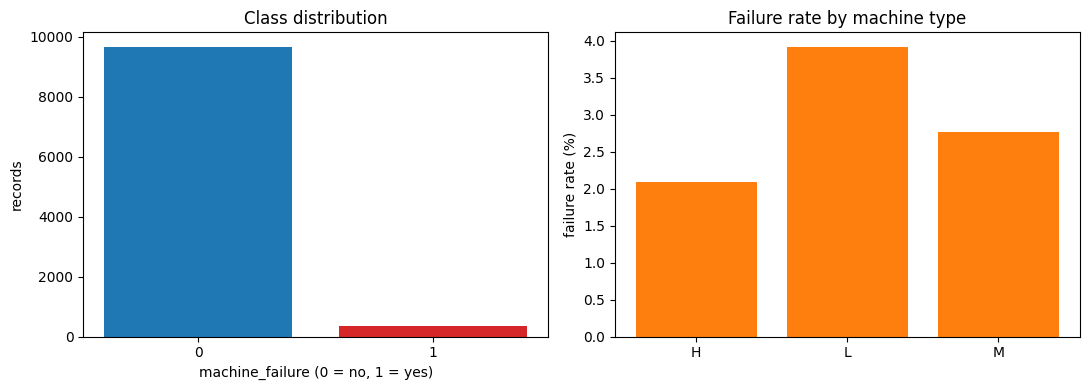

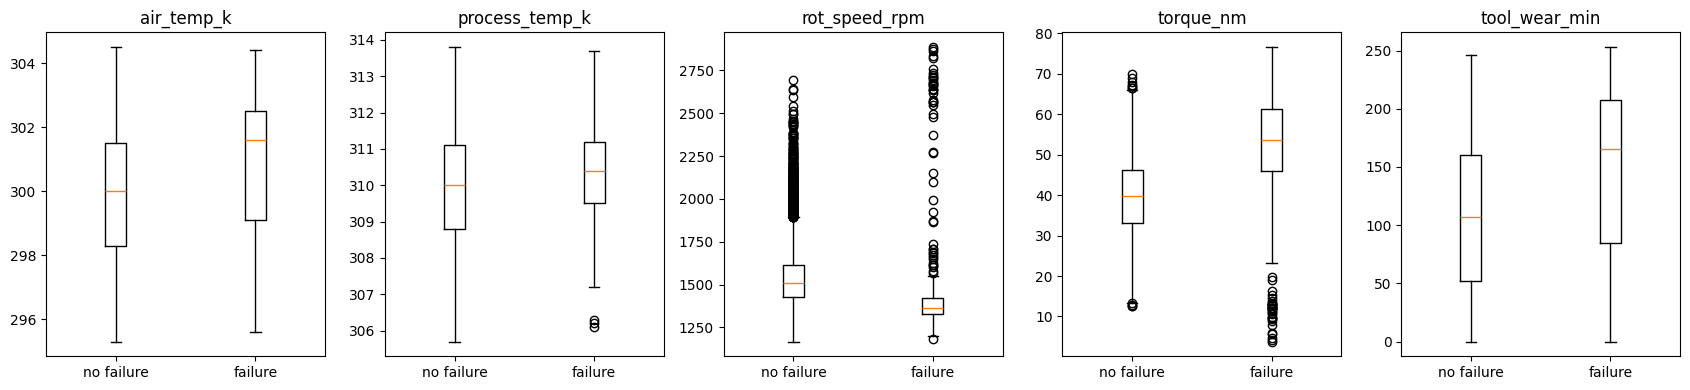

In [14]:
# 3.5 Visualisations (small aggregated results / 10k-row selection converted to pandas for plotting only)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

class_pdf = df.groupBy(TARGET).count().orderBy(TARGET).toPandas()
axes[0].bar(class_pdf[TARGET].astype(str), class_pdf["count"], color=["tab:blue", "tab:red"])
axes[0].set_title("Class distribution")
axes[0].set_xlabel("machine_failure (0 = no, 1 = yes)")
axes[0].set_ylabel("records")

type_pdf = df.groupBy("machine_type").agg(F.avg(TARGET).alias("rate")).orderBy("machine_type").toPandas()
axes[1].bar(type_pdf["machine_type"], type_pdf["rate"] * 100, color="tab:orange")
axes[1].set_title("Failure rate by machine type")
axes[1].set_ylabel("failure rate (%)")
plt.tight_layout()
plt.show()

# Box plots of each sensor for failed vs not-failed machines
box_pdf = df.select(RAW_NUMERIC_COLS + [TARGET]).toPandas()
fig, axes = plt.subplots(1, len(RAW_NUMERIC_COLS), figsize=(17, 4))
for ax, c in zip(axes, RAW_NUMERIC_COLS):
    ax.boxplot([box_pdf.loc[box_pdf[TARGET] == 0, c], box_pdf.loc[box_pdf[TARGET] == 1, c]])
    ax.set_xticklabels(["no failure", "failure"])
    ax.set_title(c)
plt.tight_layout()
plt.show()

## Section 4: Data preprocessing and feature design

**Target:** `label` = `machine_failure` cast to double (MLlib expects a numeric label; positive class = 1.0 = failure).

**Features used (inputs)**
| Group | Columns |
|---|---|
| Numeric sensors | `air_temp_k`, `process_temp_k`, `rot_speed_rpm`, `torque_nm`, `tool_wear_min` |
| Categorical | `machine_type` (L/M/H) -> StringIndexer + OneHotEncoder |
| Derived from the sensors above | `temp_diff_k` = process temp - air temp; `power_w` = torque x angular speed (physically meaningful quantities built only from input sensors, so no target leakage) |

**Excluded and why**
* `UDI`, `product_id`: row identifiers with no predictive meaning (and `product_id` is almost unique per row, so a model could memorise it).
* `machine_failure`: this *is* the target.
* `TWF, HDF, PWF, OSF, RNF`: failure-mode flags. They are outcomes that describe the failure itself, so using them would leak the answer.

**Scaling:** only Logistic Regression is sensitive to feature scale, so it gets a `StandardScaler`. Decision Tree and Random Forest split on thresholds and do not need scaling.

All feature engineering is placed *inside the MLlib Pipeline* (via `SQLTransformer`). That guarantees training, testing and new-machine predictions use exactly the same steps, and the saved model carries them too.

In [15]:
# 4.1 Clean the data: types, missing values, duplicates, target column
clean_df = df
for c in RAW_NUMERIC_COLS:                              # force numeric sensors to double
    clean_df = clean_df.withColumn(c, F.col(c).cast("double"))
for c in FAILURE_MODE_COLS + [TARGET]:                  # flags to integer
    clean_df = clean_df.withColumn(c, F.col(c).cast("int"))

rows_before = clean_df.count()

# Missing values: drop rows with a null/NaN in anything the model needs (Spark's dropna removes null and NaN)
clean_df = clean_df.dropna(subset=RAW_NUMERIC_COLS + CATEGORICAL_COLS + [TARGET])
rows_after_na = clean_df.count()

# Duplicates: remove rows identical in every column except the running index UDI
clean_df = clean_df.dropDuplicates([c for c in clean_df.columns if c != "UDI"])

# Define the MLlib label (double). Positive class = 1.0 = machine failure.
clean_df = clean_df.withColumn("label", F.col(TARGET).cast("double")).cache()
rows_after = clean_df.count()

print("Rows before cleaning           :", rows_before)
print("Rows after dropping missing    :", rows_after_na)
print("Rows after dropping duplicates :", rows_after)
assert clean_df.select("UDI").distinct().count() == rows_after, "UDI must be unique for the split logic below."
clean_df.printSchema()

Rows before cleaning           : 10000
Rows after dropping missing    : 10000
Rows after dropping duplicates : 10000
root
 |-- UDI: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- machine_type: string (nullable = true)
 |-- air_temp_k: double (nullable = true)
 |-- process_temp_k: double (nullable = true)
 |-- rot_speed_rpm: double (nullable = true)
 |-- torque_nm: double (nullable = true)
 |-- tool_wear_min: double (nullable = true)
 |-- machine_failure: integer (nullable = true)
 |-- TWF: integer (nullable = true)
 |-- HDF: integer (nullable = true)
 |-- PWF: integer (nullable = true)
 |-- OSF: integer (nullable = true)
 |-- RNF: integer (nullable = true)
 |-- label: double (nullable = true)



In [16]:
# 4.2 Feature lists and explicit target-leakage check
ENGINEERED_COLS = ["temp_diff_k", "power_w"]
NUMERIC_FEATURES = RAW_NUMERIC_COLS + ENGINEERED_COLS
INPUT_COLUMNS_FOR_NEW_DATA = CATEGORICAL_COLS + RAW_NUMERIC_COLS    # what a user must supply for a new machine

EXCLUDED = {
    "UDI": "identifier", "product_id": "identifier (near-unique per row)",
    "machine_failure": "this is the target", "label": "numeric copy of the target",
    "TWF": "failure-mode flag (reveals the outcome)", "HDF": "failure-mode flag (reveals the outcome)",
    "PWF": "failure-mode flag (reveals the outcome)", "OSF": "failure-mode flag (reveals the outcome)",
    "RNF": "failure-mode flag (reveals the outcome)",
}
used_inputs = set(CATEGORICAL_COLS + NUMERIC_FEATURES)
leaked = used_inputs & set(EXCLUDED)
assert not leaked, f"Target leakage! These forbidden columns are used as features: {leaked}"

print("Leakage check passed. Model inputs:")
print("  categorical :", CATEGORICAL_COLS)
print("  numeric     :", NUMERIC_FEATURES)
print("\nExcluded columns:")
for k, v in EXCLUDED.items():
    print(f"  {k:16} {v}")

Leakage check passed. Model inputs:
  categorical : ['machine_type']
  numeric     : ['air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_diff_k', 'power_w']

Excluded columns:
  UDI              identifier
  product_id       identifier (near-unique per row)
  machine_failure  this is the target
  label            numeric copy of the target
  TWF              failure-mode flag (reveals the outcome)
  HDF              failure-mode flag (reveals the outcome)
  PWF              failure-mode flag (reveals the outcome)
  OSF              failure-mode flag (reveals the outcome)
  RNF              failure-mode flag (reveals the outcome)


In [17]:
# 4.3 Pipeline builder (feature engineering + encoding + assembling [+ scaling] + classifier)
def build_pipeline(classifier, scale_numeric):
    # Step 1: derive temp_diff_k and power_w from the raw sensors (power = torque * rpm * 2*pi/60 watts)
    feature_engineering = SQLTransformer(statement=(
        "SELECT *, "
        "(process_temp_k - air_temp_k) AS temp_diff_k, "
        "(torque_nm * rot_speed_rpm * 2 * 3.141592653589793 / 60) AS power_w "
        "FROM __THIS__"))
    # Step 2: encode machine_type (text) as numbers, then one-hot vectors (all 3 categories kept for readability)
    indexer = StringIndexer(inputCol="machine_type", outputCol="machine_type_idx")
    encoder = OneHotEncoder(inputCols=["machine_type_idx"], outputCols=["machine_type_vec"], dropLast=False)

    stages = [feature_engineering, indexer, encoder]
    if scale_numeric:
        # Scale ONLY the numeric columns (mean 0, std 1). Fitted on training data inside pipeline.fit().
        num_assembler = VectorAssembler(inputCols=NUMERIC_FEATURES, outputCol="numeric_raw")
        scaler = StandardScaler(inputCol="numeric_raw", outputCol="numeric_scaled", withMean=True, withStd=True)
        final_assembler = VectorAssembler(inputCols=["numeric_scaled", "machine_type_vec"], outputCol="features")
        stages += [num_assembler, scaler, final_assembler]
    else:
        final_assembler = VectorAssembler(inputCols=NUMERIC_FEATURES + ["machine_type_vec"], outputCol="features")
        stages += [final_assembler]
    stages.append(classifier)
    return Pipeline(stages=stages)

print("Pipeline builder defined.")

Pipeline builder defined.


## Section 5: Training, validation and test sets
Model *selection* must not look at the test set. So the data is split three ways with a fixed seed, **stratified by the label** (each split keeps roughly the same failure rate):

* **Train (~70%)**: fit the models.
* **Validation (~15%)**: compare the three models and pick the best one.
* **Test (~15%)**: untouched until the final evaluation.

Preprocessing (`StringIndexer`, `StandardScaler`) is fitted inside `pipeline.fit(train_df)`, so it only ever learns from training data.

**Class imbalance:** failures are rare, so training rows get a **class weight** (`n / (2 x class_count)`, computed from the training set only). Failure rows then count more during training. Validation and test data are *not* resampled or reweighted, so evaluation reflects the real class mix.

In [18]:
# 5.1 Stratified train / validation / test split (reproducible, seed = 42)
labels_fraction = lambda f: {0.0: f, 1.0: f}

train_df = clean_df.sampleBy("label", labels_fraction(0.70), seed=SEED)
remaining_df = clean_df.join(train_df.select("UDI"), on="UDI", how="left_anti")      # everything not in train
val_df = remaining_df.sampleBy("label", labels_fraction(0.50), seed=SEED)             # half of the remainder
test_df = remaining_df.join(val_df.select("UDI"), on="UDI", how="left_anti")          # the other half

train_df, val_df, test_df = train_df.cache(), val_df.cache(), test_df.cache()
n_train, n_val, n_test = train_df.count(), val_df.count(), test_df.count()

# Sanity checks: no overlap and nothing lost
assert n_train + n_val + n_test == rows_after
assert train_df.join(val_df, "UDI").count() == 0
assert train_df.join(test_df, "UDI").count() == 0
assert val_df.join(test_df, "UDI").count() == 0

print(f"train: {n_train}   validation: {n_val}   test: {n_test}   (total {rows_after})\n")
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    stats = part.agg(F.count("*").alias("rows"), F.sum("label").alias("failures"),
                     F.round(F.avg("label") * 100, 2).alias("failure_rate_pct")).collect()[0]
    print(f"{name:11} rows={stats['rows']:5d}  failures={int(stats['failures']):4d}  failure rate={stats['failure_rate_pct']}%")

train: 7068   validation: 1485   test: 1447   (total 10000)

train       rows= 7068  failures= 240  failure rate=3.4%
validation  rows= 1485  failures=  48  failure rate=3.23%
test        rows= 1447  failures=  51  failure rate=3.52%


In [19]:
# 5.2 Class weights computed from the TRAINING set only
class_counts = {row["label"]: row["count"] for row in train_df.groupBy("label").count().collect()}
weight_for_class = {lab: n_train / (2.0 * cnt) for lab, cnt in class_counts.items()}
print("Training class counts :", class_counts)
print("Class weights         :", {k: round(v, 3) for k, v in weight_for_class.items()})

train_df = train_df.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(weight_for_class[1.0])).otherwise(F.lit(weight_for_class[0.0])))
train_df = train_df.cache()
train_df.groupBy("label").agg(F.count("*").alias("rows"), F.first("class_weight").alias("weight")).show()

Training class counts : {1.0: 240, 0.0: 6828}
Class weights         : {1.0: 14.725, 0.0: 0.518}
+-----+----+------------------+
|label|rows|            weight|
+-----+----+------------------+
|  1.0| 240|            14.725|
|  0.0|6828|0.5175746924428822|
+-----+----+------------------+



## Section 6: Model training (Spark MLlib)
Three classifiers, each wrapped in its own Pipeline with sensible default-style parameters (no heavy tuning, to keep Colab fast):

| Model | Notes |
|---|---|
| Logistic Regression | linear model; numeric features **are scaled**; `weightCol` handles imbalance |
| Decision Tree | `maxDepth=5`; no scaling needed; `weightCol` handles imbalance |
| Random Forest | 100 trees, `maxDepth=8`; no scaling needed; `weightCol` handles imbalance |

Each fitted pipeline is applied to the validation and the test DataFrames. The prediction DataFrames keep the true `label`, the `prediction`, and the `probability`/`rawPrediction` vectors.

In [20]:
# 6.1 Define the three models and fit them on the training data
model_specs = {
    "Logistic Regression": (LogisticRegression(featuresCol="features", labelCol="label", weightCol="class_weight",
                                               maxIter=100, regParam=0.01, elasticNetParam=0.0), True),
    "Decision Tree":       (DecisionTreeClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                                                   maxDepth=5, seed=SEED), False),
    "Random Forest":       (RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                                                   numTrees=100, maxDepth=8, seed=SEED), False),
}

models = {}
for name, (classifier, scale) in model_specs.items():
    start = time.time()
    models[name] = build_pipeline(classifier, scale_numeric=scale).fit(train_df)   # fits indexer/scaler/model on TRAIN only
    print(f"{name:20} trained in {time.time() - start:5.1f} s")

Logistic Regression  trained in  15.7 s
Decision Tree        trained in   5.1 s
Random Forest        trained in  15.7 s


In [21]:
# 6.2 Generate predictions on validation and test data
val_preds, test_preds = {}, {}
for name, model in models.items():
    val_preds[name] = model.transform(val_df).cache()
    test_preds[name] = model.transform(test_df).cache()

for name in models:
    print("=" * 70)
    print(name, "- first test predictions (label = actual, prediction = predicted)")
    test_preds[name].select("UDI", "label", "prediction", "probability").show(5, truncate=False)
    print("Predicted class counts on the test set:")
    test_preds[name].groupBy("prediction").count().orderBy("prediction").show()

Logistic Regression - first test predictions (label = actual, prediction = predicted)
+---+-----+----------+----------------------------------------+
|UDI|label|prediction|probability                             |
+---+-----+----------+----------------------------------------+
|21 |0.0  |0.0       |[0.928986899642708,0.07101310035729202] |
|64 |0.0  |0.0       |[0.7831295949400273,0.21687040505997268]|
|95 |0.0  |0.0       |[0.915255003674331,0.08474499632566901] |
|144|0.0  |1.0       |[0.390332464320727,0.609667535679273]   |
|159|0.0  |0.0       |[0.577499458659604,0.42250054134039605] |
+---+-----+----------+----------------------------------------+
only showing top 5 rows
Predicted class counts on the test set:
+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 1155|
|       1.0|  292|
+----------+-----+

Decision Tree - first test predictions (label = actual, prediction = predicted)
+---+-----+----------+----------------------------------------+
|UDI|label|pred

## Section 7: Model evaluation
**Positive class = failure (label 1.0).** Metrics below are computed for that class:
* **Precision** = of the machines flagged as failing, how many really failed.
* **Recall** = of the machines that really failed, how many we caught.
* **F1** = harmonic mean of precision and recall; **F2** weights recall more heavily.
* **ROC-AUC / PR-AUC** = threshold-independent ranking quality. With rare failures, PR-AUC is usually the more informative of the two.

**Why recall on the failure class matters most:** a *false negative* means a machine that is about to fail was predicted healthy, so it gets no inspection and may break unexpectedly (downtime, cost, safety). A *false positive* usually costs only an unnecessary inspection. That is why we do not choose a model by accuracy alone.

**Selection rule (uses the validation set only):** highest failure-class **F2** score, with PR-AUC as tie-breaker. The test set is used only to report final, unbiased numbers.

In [22]:
# 7.1 Evaluation helper: metrics for the POSITIVE class (failure = 1.0), computed from the confusion matrix
roc_evaluator = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_evaluator = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def safe_div(a, b):
    return a / b if b else 0.0

def evaluate_model(pred_df, model_name, split_name):
    counts = {(float(r["label"]), float(r["prediction"])): r["count"]
              for r in pred_df.groupBy("label", "prediction").count().collect()}
    tp, fp = counts.get((1.0, 1.0), 0), counts.get((0.0, 1.0), 0)
    fn, tn = counts.get((1.0, 0.0), 0), counts.get((0.0, 0.0), 0)
    precision = safe_div(tp, tp + fp)
    recall = safe_div(tp, tp + fn)
    f1 = safe_div(2 * precision * recall, precision + recall)
    f2 = safe_div(5 * precision * recall, 4 * precision + recall)       # F-beta with beta = 2 (recall-weighted)
    return {
        "Model": model_name, "Split": split_name,
        "Accuracy": safe_div(tp + tn, tp + tn + fp + fn),
        "Precision_failure": precision, "Recall_failure": recall,
        "F1_failure": f1, "F2_failure": f2,
        "ROC_AUC": roc_evaluator.evaluate(pred_df), "PR_AUC": pr_evaluator.evaluate(pred_df),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

# 7.2 Validation results -> used for MODEL SELECTION
val_results = pd.DataFrame([evaluate_model(val_preds[n], n, "validation") for n in models])
print("VALIDATION metrics (failure = positive class):")
display(val_results.round(4))

best_row = val_results.sort_values(["F2_failure", "PR_AUC"], ascending=False).iloc[0]
best_model_name = best_row["Model"]
print(f"\nSelected model (best validation F2, PR-AUC as tie-breaker): {best_model_name}")

VALIDATION metrics (failure = positive class):


,Model,Split,Accuracy,Precision_failure,Recall_failure,F1_failure,F2_failure,ROC_AUC,PR_AUC,TP,FP,FN,TN
0,Logistic Regression,validation,0.8094,0.1317,0.8750,0.2289,0.4110,0.9193,0.4180,42,277,6,1160
1,Decision Tree,validation,0.9286,0.3014,0.9167,0.4536,0.6509,0.7798,0.5294,44,102,4,1335
2,Random Forest,validation,0.9865,0.7800,0.8125,0.7959,0.8058,0.9890,0.8766,39,11,9,1426



Selected model (best validation F2, PR-AUC as tie-breaker): Random Forest


TEST metrics (failure = positive class):


,Model,Split,Accuracy,Precision_failure,Recall_failure,F1_failure,F2_failure,ROC_AUC,PR_AUC,TP,FP,FN,TN
0,Logistic Regression,test,0.8100,0.1164,0.6667,0.1983,0.3427,0.8586,0.3654,34,258,17,1138
1,Decision Tree,test,0.9281,0.3172,0.9020,0.4694,0.6590,0.8323,0.6064,46,99,5,1297
2,Random Forest,test,0.9793,0.6909,0.7451,0.7170,0.7336,0.9854,0.7871,38,17,13,1379


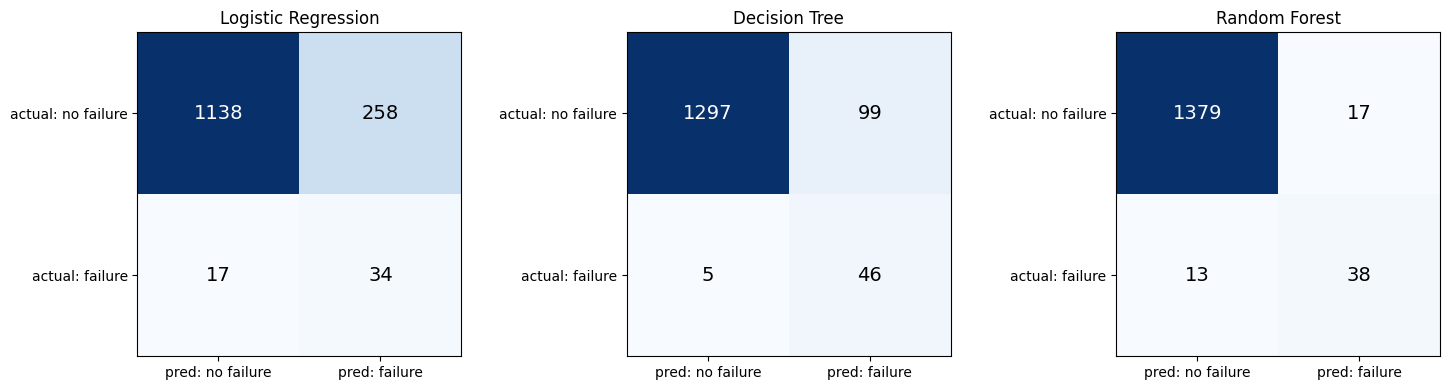

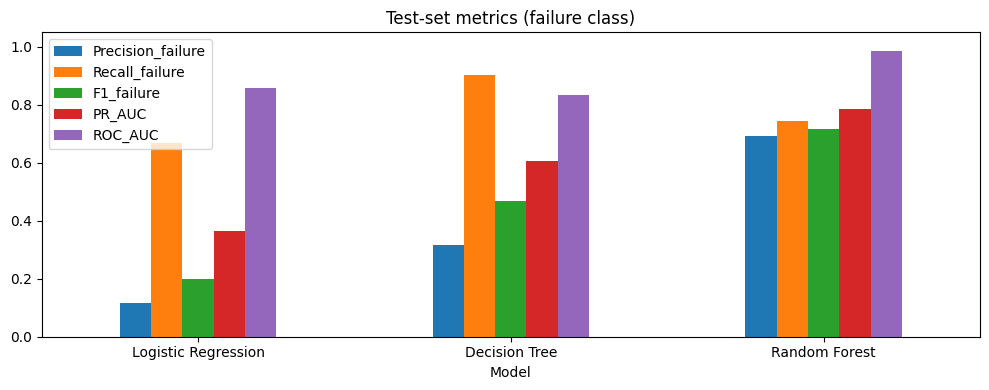

In [23]:
# 7.3 Final TEST results for all three models (the test set was NOT used for the selection above)
test_results = pd.DataFrame([evaluate_model(test_preds[n], n, "test") for n in models])
print("TEST metrics (failure = positive class):")
display(test_results.round(4))

# Confusion matrices (rows = actual, columns = predicted)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (_, row) in zip(axes, test_results.iterrows()):
    matrix = [[row["TN"], row["FP"]], [row["FN"], row["TP"]]]
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(row["Model"])
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred: no failure", "pred: failure"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["actual: no failure", "actual: failure"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(matrix[i][j]), ha="center", va="center", fontsize=14,
                    color="white" if matrix[i][j] > max(max(r) for r in matrix) / 2 else "black")
plt.tight_layout()
plt.show()

# Side-by-side bar chart of the failure-class metrics
plot_cols = ["Precision_failure", "Recall_failure", "F1_failure", "PR_AUC", "ROC_AUC"]
test_results.set_index("Model")[plot_cols].plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Test-set metrics (failure class)")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [24]:
# 7.4 Cross-check with Spark's built-in evaluator: positive-class metrics vs WEIGHTED averages
# (weighted metrics are dominated by the majority "no failure" class and look much better than the real failure detection)
best_test_pred = test_preds[best_model_name]
mc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricLabel=1.0)
print(f"Cross-check for {best_model_name} on the test set")
print("Positive-class (failure) metrics from Spark:")
for metric in ["precisionByLabel", "recallByLabel", "fMeasureByLabel"]:
    print(f"  {metric:18} {mc.setMetricName(metric).evaluate(best_test_pred):.4f}")
print("Weighted-average metrics from Spark (NOT the failure-class numbers):")
for metric in ["accuracy", "weightedPrecision", "weightedRecall", "weightedFMeasure"]:
    print(f"  {metric:18} {mc.setMetricName(metric).evaluate(best_test_pred):.4f}")
row = test_results[test_results["Model"] == best_model_name].iloc[0]
print(f"\nOur manual failure-class values: precision={row['Precision_failure']:.4f}, recall={row['Recall_failure']:.4f}, F1={row['F1_failure']:.4f}")
print("The 'ByLabel' values above should match these.")

Cross-check for Random Forest on the test set
Positive-class (failure) metrics from Spark:
  precisionByLabel   0.6909
  recallByLabel      0.7451
  fMeasureByLabel    0.7170
Weighted-average metrics from Spark (NOT the failure-class numbers):
  accuracy           0.9793
  weightedPrecision  0.9801
  weightedRecall     0.9793
  weightedFMeasure   0.9796

Our manual failure-class values: precision=0.6909, recall=0.7451, F1=0.7170
The 'ByLabel' values above should match these.


In [25]:
# 7.5 Summary of the model choice
sel_val = val_results[val_results["Model"] == best_model_name].iloc[0]
sel_test = test_results[test_results["Model"] == best_model_name].iloc[0]
print(f"Selected model: {best_model_name}")
print(f"  validation: recall={sel_val['Recall_failure']:.3f}  precision={sel_val['Precision_failure']:.3f}  F2={sel_val['F2_failure']:.3f}  PR-AUC={sel_val['PR_AUC']:.3f}")
print(f"  test      : recall={sel_test['Recall_failure']:.3f}  precision={sel_test['Precision_failure']:.3f}  F2={sel_test['F2_failure']:.3f}  PR-AUC={sel_test['PR_AUC']:.3f}")
print(f"  test confusion counts: TP={sel_test['TP']}  FN={sel_test['FN']} (missed failures)  FP={sel_test['FP']} (false alarms)  TN={sel_test['TN']}")
print("\nCaution: the validation and test sets each contain only a few dozen failures, so these metrics are noisy.")
print("A different random seed could change the ranking of close models.")
best_model = models[best_model_name]

Selected model: Random Forest
  validation: recall=0.812  precision=0.780  F2=0.806  PR-AUC=0.877
  test      : recall=0.745  precision=0.691  F2=0.734  PR-AUC=0.787
  test confusion counts: TP=38  FN=13 (missed failures)  FP=17 (false alarms)  TN=1379

Caution: the validation and test sets each contain only a few dozen failures, so these metrics are noisy.
A different random seed could change the ranking of close models.


## Section 8: Feature importance and failure analysis
Tree models expose `featureImportances` (how much each feature reduced impurity across the splits). Logistic Regression coefficients are shown for the *scaled* features as a rough linear view.

**Important:** these are *associations learned from this dataset*, not proof of causes. Feature importance says what the model relies on, not why machines fail physically. (AI4I 2020 is also a synthetic dataset, so patterns reflect how the data was generated.)

Feature vector layout: ['air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_diff_k', 'power_w', 'machine_type_vec_L', 'machine_type_vec_M', 'machine_type_vec_H']

Top features - Decision Tree:


,feature,importance
0,rot_speed_rpm,0.3721
1,power_w,0.2527
2,tool_wear_min,0.2073
3,torque_nm,0.1094
4,temp_diff_k,0.0504
5,process_temp_k,0.0044
6,air_temp_k,0.0020
7,machine_type_vec_M,0.0017
8,machine_type_vec_L,0.0000
9,machine_type_vec_H,0.0000



Top features - Random Forest:


,feature,importance
0,torque_nm,0.2315
1,rot_speed_rpm,0.2149
2,tool_wear_min,0.2049
3,power_w,0.1586
4,temp_diff_k,0.1064
5,air_temp_k,0.0415
6,process_temp_k,0.0277
7,machine_type_vec_L,0.0076
8,machine_type_vec_M,0.0044
9,machine_type_vec_H,0.0025


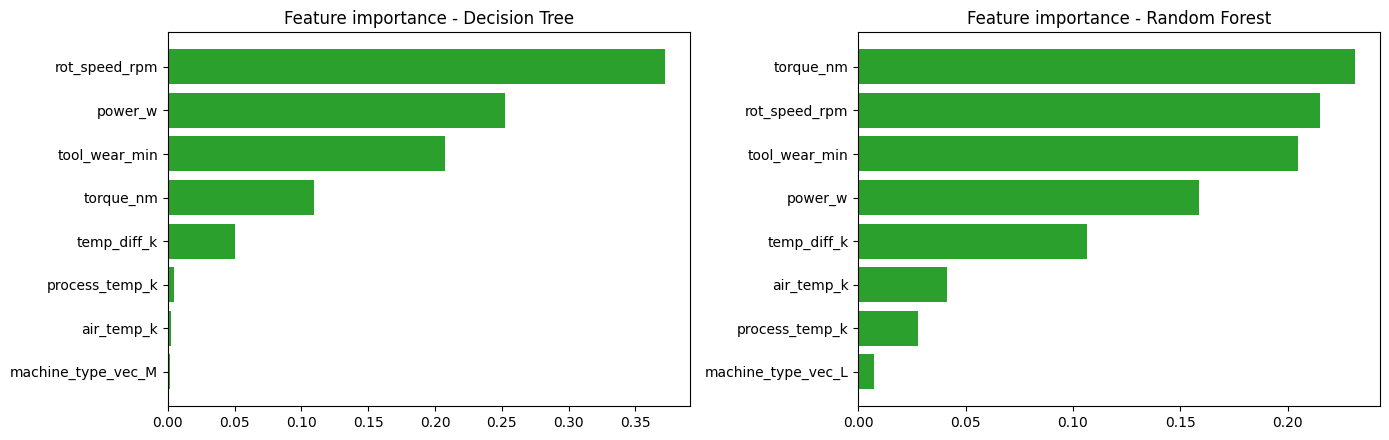

Logistic Regression coefficients (positive = pushes toward 'failure'):


,feature,coefficient
3,torque_nm,1.3756
2,rot_speed_rpm,1.0345
4,tool_wear_min,0.6689
5,temp_diff_k,-0.5646
0,air_temp_k,0.2409
6,power_w,0.2045
8,machine_type_vec_M,-0.1706
7,machine_type_vec_L,0.1657
1,process_temp_k,-0.1491
9,machine_type_vec_H,-0.0595


In [26]:
# 8.1 Feature importances from the tree models
def get_feature_names(transformed_df, features_col="features"):
    # Reads the feature names that VectorAssembler stores in the column metadata.
    attrs = transformed_df.schema[features_col].metadata["ml_attr"]["attrs"]
    flat = [a for group in attrs.values() for a in group]
    flat.sort(key=lambda a: a["idx"])
    return [a["name"] for a in flat]

sample_transformed = models["Random Forest"].transform(test_df.limit(5))
try:
    feature_names = get_feature_names(sample_transformed)
except Exception:
    n_feat = len(sample_transformed.select("features").first()[0])
    feature_names = [f"feature_{i}" for i in range(n_feat)]
print("Feature vector layout:", feature_names)

importance_tables = {}
for name in ["Decision Tree", "Random Forest"]:
    fitted_classifier = models[name].stages[-1]
    importances = fitted_classifier.featureImportances.toArray()
    importance_tables[name] = (pd.DataFrame({"feature": feature_names, "importance": importances})
                               .sort_values("importance", ascending=False).reset_index(drop=True))
    print(f"\nTop features - {name}:")
    display(importance_tables[name].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, importance_tables):
    t = importance_tables[name].head(8).iloc[::-1]
    ax.barh(t["feature"], t["importance"], color="tab:green")
    ax.set_title(f"Feature importance - {name}")
plt.tight_layout()
plt.show()

# Logistic Regression coefficients (numeric features are standardised, so magnitudes are comparable)
lr_coefs = models["Logistic Regression"].stages[-1].coefficients.toArray()
if len(lr_coefs) == len(feature_names):
    print("Logistic Regression coefficients (positive = pushes toward 'failure'):")
    display(pd.DataFrame({"feature": feature_names, "coefficient": lr_coefs})
            .sort_values("coefficient", key=abs, ascending=False).round(4))

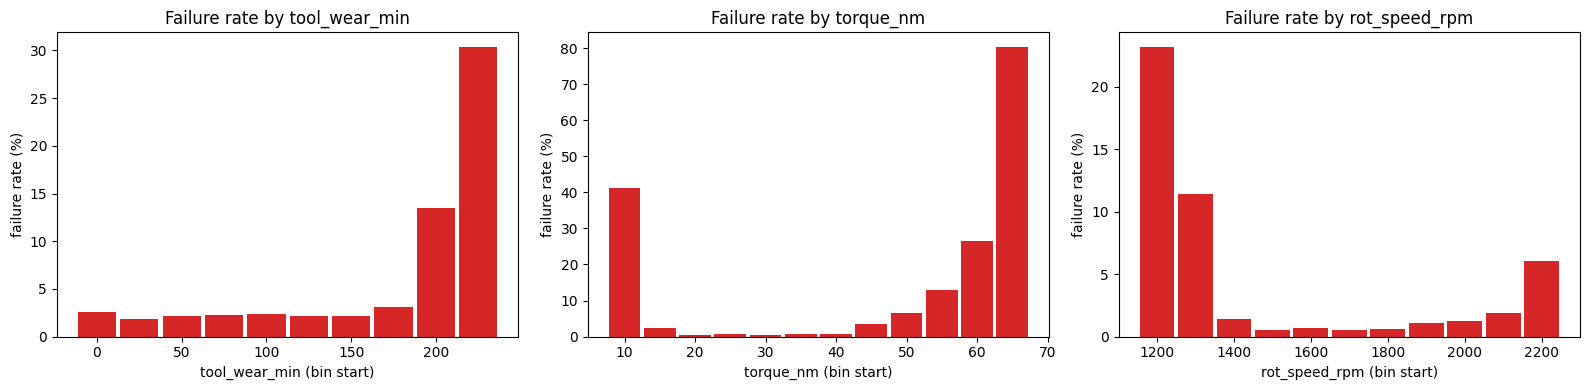

Bins with fewer than 20 records are hidden. These are associations in this data, not causal proof.


In [27]:
# 8.2 Failure patterns in the data: failure rate across ranges of key sensors (Spark aggregation, then plot)
def failure_rate_by_bin(column, bin_width):
    return (clean_df.withColumn("bin", F.floor(F.col(column) / bin_width) * bin_width)
            .groupBy("bin").agg(F.count("*").alias("n"), F.avg("label").alias("failure_rate"))
            .orderBy("bin").toPandas())

bin_specs = [("tool_wear_min", 25), ("torque_nm", 5), ("rot_speed_rpm", 100)]
fig, axes = plt.subplots(1, len(bin_specs), figsize=(16, 4))
for ax, (col_name, width) in zip(axes, bin_specs):
    pdf = failure_rate_by_bin(col_name, width)
    pdf = pdf[pdf["n"] >= 20]                       # hide bins with very few records (noisy rates)
    ax.bar(pdf["bin"], pdf["failure_rate"] * 100, width=width * 0.9, color="tab:red")
    ax.set_title(f"Failure rate by {col_name}")
    ax.set_xlabel(f"{col_name} (bin start)")
    ax.set_ylabel("failure rate (%)")
plt.tight_layout()
plt.show()
print("Bins with fewer than 20 records are hidden. These are associations in this data, not causal proof.")

In [28]:
# 8.3 What do caught vs missed failures look like? (selected model, test set)
outcome = (F.when((F.col("label") == 1.0) & (F.col("prediction") == 1.0), "TP (failure caught)")
            .when((F.col("label") == 1.0) & (F.col("prediction") == 0.0), "FN (failure missed)")
            .when((F.col("label") == 0.0) & (F.col("prediction") == 1.0), "FP (false alarm)")
            .otherwise("TN (correctly healthy)"))
print(f"Average sensor values by prediction outcome - {best_model_name}, test set:")
(best_test_pred.withColumn("outcome", outcome)
    .groupBy("outcome")
    .agg(F.count("*").alias("n"), *[F.round(F.avg(c), 2).alias(c) for c in RAW_NUMERIC_COLS + ENGINEERED_COLS])
    .orderBy("outcome").show(truncate=False))

# Failure-mode flags were NOT used for training; here they are used only to analyse the results afterwards.
print(f"How many real failures of each mode does {best_model_name} catch on the test set?")
mode_rows = []
for mode in FAILURE_MODE_COLS:
    subset = best_test_pred.filter(F.col(mode) == 1)
    n_mode = subset.count()
    caught = subset.filter(F.col("prediction") == 1.0).count()
    mode_rows.append({"failure_mode": mode, "records_in_test": n_mode, "caught": caught,
                      "recall": round(caught / n_mode, 3) if n_mode else None})
display(pd.DataFrame(mode_rows))
print("TWF = tool wear, HDF = heat dissipation, PWF = power, OSF = overstrain, RNF = random failure.")
print("Modes with very few test records give unreliable recall values.")

Average sensor values by prediction outcome - Random Forest, test set:
+----------------------+----+----------+--------------+-------------+---------+-------------+-----------+-------+
|outcome               |n   |air_temp_k|process_temp_k|rot_speed_rpm|torque_nm|tool_wear_min|temp_diff_k|power_w|
+----------------------+----+----------+--------------+-------------+---------+-------------+-----------+-------+
|FN (failure missed)   |13  |299.42    |309.76        |1630.31      |36.88    |209.69       |10.35      |5934.45|
|FP (false alarm)      |17  |301.02    |310.65        |1455.88      |45.55    |176.76       |9.63       |6801.66|
|TN (correctly healthy)|1379|299.88    |309.91        |1538.37      |39.64    |104.11       |10.03      |6247.72|
|TP (failure caught)   |38  |301.84    |310.95        |1506.63      |51.38    |121.82       |9.12       |7332.8 |
+----------------------+----+----------+--------------+-------------+---------+-------------+-----------+-------+

How many real fa

,failure_mode,records_in_test,caught,recall
0,TWF,10,0,0.000
1,HDF,19,19,1.000
2,PWF,17,15,0.882
3,OSF,9,7,0.778
4,RNF,3,1,0.333


TWF = tool wear, HDF = heat dissipation, PWF = power, OSF = overstrain, RNF = random failure.
Modes with very few test records give unreliable recall values.


## Section 9: Demonstrating predictions
The selected pipeline predicts for unseen test machines. The output has human-readable labels and a **failure probability** (class-1 probability from the model).

**Important:**
* A prediction is an **indication of risk, not a guarantee** that a machine will or will not fail.
* Because the models were trained with class weights, the probability is a **risk score for ranking** machines, not a calibrated real-world probability of failure.

In [29]:
# 9.1 Convert model output into readable risk information
def add_risk_columns(pred_df):
    out = (pred_df
           .withColumn("failure_probability", F.round(vector_to_array(F.col("probability"))[1], 4))   # P(class = 1)
           .withColumn("predicted_label", F.col("prediction").cast("int"))
           .withColumn("risk_status", F.when(F.col("prediction") == 1.0, "Potential failure detected")
                                       .otherwise("No failure predicted")))
    if "label" in pred_df.columns:
        out = out.withColumn("actual_label", F.col("label").cast("int"))
    return out

scored = add_risk_columns(test_preds[best_model_name]).cache()
display_cols = ["UDI", "machine_type"] + RAW_NUMERIC_COLS + ["actual_label", "predicted_label", "failure_probability", "risk_status"]

print(f"Sample of test predictions ({best_model_name}):")
display(scored.select(display_cols).limit(10).toPandas())

print("Highest-risk test machines:")
display(scored.orderBy(F.col("failure_probability").desc()).select(display_cols).limit(10).toPandas())

Sample of test predictions (Random Forest):


,UDI,machine_type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,actual_label,predicted_label,failure_probability,risk_status
0,21,H,298.9,309.3,1375.0,42.7,58.0,0,0,0.0102,No failure predicted
1,64,M,298.9,309.0,1812.0,25.9,174.0,0,0,0.1828,No failure predicted
2,95,L,299.0,308.9,1622.0,31.9,42.0,0,0,0.0207,No failure predicted
3,144,H,298.6,308.4,1407.0,50.5,164.0,0,0,0.0156,No failure predicted
4,159,M,298.4,308.2,1499.0,40.0,211.0,0,0,0.2053,No failure predicted
5,171,M,298.4,308.2,1610.0,35.0,24.0,0,0,0.0201,No failure predicted
6,194,H,298.2,308.4,1678.0,34.6,81.0,0,0,0.0189,No failure predicted
7,200,L,298.4,308.6,1433.0,47.1,101.0,0,0,0.0307,No failure predicted
8,256,L,298.0,308.2,1489.0,40.4,11.0,0,0,0.0171,No failure predicted
9,271,H,298.0,308.0,1520.0,39.6,51.0,0,0,0.0172,No failure predicted


Highest-risk test machines:


,UDI,machine_type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,actual_label,predicted_label,failure_probability,risk_status
0,6800,M,301.1,310.7,2636.0,12.2,100.0,1,1,0.9900,Potential failure detected
1,7998,M,301.0,312.2,2710.0,9.7,143.0,1,1,0.9800,Potential failure detected
2,7537,L,300.1,311.3,2579.0,12.5,64.0,1,1,0.9800,Potential failure detected
3,1392,L,298.9,310.2,2737.0,8.8,142.0,1,1,0.9758,Potential failure detected
4,7281,L,299.9,310.2,1288.0,69.6,62.0,1,1,0.9726,Potential failure detected
5,4343,M,301.7,309.8,1284.0,68.2,111.0,1,1,0.9562,Potential failure detected
6,4436,L,302.3,310.1,1321.0,52.7,134.0,1,1,0.9541,Potential failure detected
7,3580,L,301.8,310.6,2672.0,11.8,124.0,1,1,0.9505,Potential failure detected
8,2706,L,299.7,309.2,1326.0,64.8,71.0,0,1,0.9441,Potential failure detected
9,4185,L,302.2,310.6,1334.0,53.2,159.0,1,1,0.9236,Potential failure detected


In [30]:
# 9.2 Use the predictions to prioritise maintenance inspections
# Idea: rank machines by risk score and inspect the top X% first. How many real failures would that find?
n_scored = scored.count()
total_failures = scored.filter(F.col("actual_label") == 1).count()
ranked = scored.withColumn("risk_rank", F.row_number().over(
    Window.orderBy(F.col("failure_probability").desc(), F.col("UDI"))))   # ties broken by UDI (arbitrary but fixed)

rows = []
for pct in (0.05, 0.10, 0.20, 0.30):
    k = max(1, int(round(n_scored * pct)))
    caught = ranked.filter((F.col("risk_rank") <= k) & (F.col("actual_label") == 1)).count()
    rows.append({"inspect_top_percent": int(pct * 100), "machines_inspected": k,
                 "failures_found": caught, "total_failures_in_test": total_failures,
                 "share_of_failures_found_%": round(100 * caught / total_failures, 1) if total_failures else None})
display(pd.DataFrame(rows))
print("Compare: inspecting machines in RANDOM order would find only about the same % of failures as the % of machines inspected.")

,inspect_top_percent,machines_inspected,failures_found,total_failures_in_test,share_of_failures_found_%
0,5,72,42,51,82.4
1,10,145,48,51,94.1
2,20,289,51,51,100.0
3,30,434,51,51,100.0


Compare: inspecting machines in RANDOM order would find only about the same % of failures as the % of machines inspected.


In [31]:
# 9.3 Predict for a NEW machine from raw sensor measurements.
# The same fitted pipeline (feature engineering, encoding, scaling if any, model) is applied, so the schema must match.
NEW_MACHINE_SCHEMA = StructType([
    StructField("machine_type", StringType(), False),
    StructField("air_temp_k", DoubleType(), False),
    StructField("process_temp_k", DoubleType(), False),
    StructField("rot_speed_rpm", DoubleType(), False),
    StructField("torque_nm", DoubleType(), False),
    StructField("tool_wear_min", DoubleType(), False),
])
assert [f.name for f in NEW_MACHINE_SCHEMA.fields] == INPUT_COLUMNS_FOR_NEW_DATA
KNOWN_TYPES = sorted(r["machine_type"] for r in train_df.select("machine_type").distinct().collect())

def predict_new_machines(model, machines):
    # machines: list of tuples (machine_type, air_temp_k, process_temp_k, rot_speed_rpm, torque_nm, tool_wear_min)
    cleaned = []
    for m in machines:
        mtype = str(m[0]).strip().upper()
        if mtype not in KNOWN_TYPES:
            raise ValueError(f"machine_type must be one of {KNOWN_TYPES}, got '{m[0]}'")
        cleaned.append((mtype,) + tuple(float(v) for v in m[1:]))
    new_df = spark.createDataFrame(cleaned, schema=NEW_MACHINE_SCHEMA)
    result = add_risk_columns(model.transform(new_df))
    return result.select(INPUT_COLUMNS_FOR_NEW_DATA + ["failure_probability", "risk_status"]).toPandas()

# Example values are illustrative only; replace them with real measurements.
example_machines = [
    ("L", 298.1, 308.6, 1551, 42.8, 0),      # moderate load, new tool
    ("M", 300.5, 310.2, 1380, 62.0, 230),    # high torque, low speed, heavily worn tool
    ("H", 302.0, 311.0, 2500, 15.0, 100),    # high speed, low torque
]
print(f"New-machine predictions using {best_model_name}:")
display(predict_new_machines(best_model, example_machines))
print("These outputs indicate risk based on patterns in the training data; they do not guarantee an outcome.")

New-machine predictions using Random Forest:


,machine_type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,failure_probability,risk_status
0,L,298.1,308.6,1551.0,42.8,0.0,0.0180,No failure predicted
1,M,300.5,310.2,1380.0,62.0,230.0,0.5913,Potential failure detected
2,H,302.0,311.0,2500.0,15.0,100.0,0.0355,No failure predicted


These outputs indicate risk based on patterns in the training data; they do not guarantee an outcome.


## Section 10: Save and reload the model
The whole fitted `PipelineModel` is saved, including the feature engineering, encoder (and scaler if used) and classifier, so loading it later gives a ready-to-use predictor. The reloaded model is checked against the original on the test set.

In [32]:
# 10.1 Save the selected pipeline, reload it, and verify identical predictions
MODEL_DIR = "/content/models/predictive_maintenance_best_model" if os.path.isdir("/content") \
            else os.path.abspath("models/predictive_maintenance_best_model")
os.makedirs(os.path.dirname(MODEL_DIR), exist_ok=True)

best_model.write().overwrite().save(MODEL_DIR)
print("Model saved to:", MODEL_DIR)
print("Saved files:", sorted(os.listdir(MODEL_DIR)))

reloaded_model = PipelineModel.load(MODEL_DIR)
print("Model reloaded. Pipeline stages:", [type(s).__name__ for s in reloaded_model.stages])

original = best_model.transform(test_df).select("UDI", F.col("prediction").alias("orig_pred"))
reloaded = reloaded_model.transform(test_df).select("UDI", F.col("prediction").alias("reload_pred"))
mismatches = original.join(reloaded, "UDI").filter(F.col("orig_pred") != F.col("reload_pred")).count()
print("Test rows where reloaded prediction differs from original:", mismatches)
assert mismatches == 0, "Reloaded model should reproduce the original predictions."

print("\nReloaded model on new-machine examples:")
display(predict_new_machines(reloaded_model, example_machines))

Model saved to: /content/models/predictive_maintenance_best_model
Saved files: ['metadata', 'stages']
Model reloaded. Pipeline stages: ['SQLTransformer', 'StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'RandomForestClassificationModel']
Test rows where reloaded prediction differs from original: 0

Reloaded model on new-machine examples:


,machine_type,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,failure_probability,risk_status
0,L,298.1,308.6,1551.0,42.8,0.0,0.0180,No failure predicted
1,M,300.5,310.2,1380.0,62.0,230.0,0.5913,Potential failure detected
2,H,302.0,311.0,2500.0,15.0,100.0,0.0355,No failure predicted


In [33]:
# 10.2 (Optional) Download the saved model from Colab as a zip file
zip_base = MODEL_DIR            # creates MODEL_DIR + ".zip"
zip_path = shutil.make_archive(zip_base, "zip", MODEL_DIR)
print("Zip created:", zip_path, "-", round(os.path.getsize(zip_path) / 1e6, 2), "MB")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab; the zip file is at the path above.")
# You can also open the Files panel (folder icon, left side), find /content/models/, right-click the zip, choose Download.
# Note: Colab storage is temporary. Download the model if you want to keep it after the session ends.

Zip created: /content/models/predictive_maintenance_best_model.zip - 0.24 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Closing notes: scalability and limits
* **What is "big data" here:** the code uses Spark DataFrames, lazy transformations, actions and MLlib Pipelines. The same code structure can run on a real cluster (for example by changing the master/cluster configuration and reading data from distributed storage), where Spark would parallelise work across machines.
* **What is not shown:** this run uses one Colab VM in local mode on ~10,000 rows. It demonstrates a correct end-to-end workflow, not large-scale performance.
* **Data limits:** AI4I 2020 is a *synthetic* dataset with few failures, so reported metrics are noisy and may not transfer to real machines.
* **Possible extensions (not done here to keep the notebook simple):** cross-validation/hyperparameter tuning with `CrossValidator`, decision-threshold tuning, and testing on genuinely large sensor logs.

## Troubleshooting common Colab errors
| Problem | Fix |
|---|---|
| `JAVA_HOME is not set` / `Java gateway process exited` | Re-run cell 1.1. If it persists: `Runtime -> Restart session`, then run all again. Spark 3.5 needs Java 8, 11 or 17 (not 21). |
| `ModuleNotFoundError: pyspark` after installing | `Runtime -> Restart session`, then run all. |
| Dataset download fails (HTTP error / timeout) | The cell automatically tries `ucimlrepo`, then asks you to upload `ai4i2020.csv` (download it from the UCI page first). |
| `Unexpected column ...` | The file's columns differ from the expected AI4I layout. Print `raw_df.columns` and update `COLUMN_MAP` in cell 2.2. |
| Spark errors about memory | Lower `spark.driver.memory` to `2g` in cell 1.2, or reduce `numTrees` in cell 6.1. |
| Session was reset (variables lost) | Run all cells again from the top, since each cell depends on the earlier ones. |
| Python/PySpark version trouble on a newer Colab image | Try `PYSPARK_VERSION = "4.0.0"` in cell 1.1 (Spark 4 needs Java 17 or newer). Not tested here. |